# Studi Kasus 5: Deteksi dan Klasifikasi Penyebab Deforestasi Hutan Tropis menggunakan Satelit dan AI

**Topik Webinar:** *Deteksi dan Klasifikasi Penyebab Deforestasi Hutan Tropis menggunakan Satelit dan AI*  
**Fokus Implementasi:** Fusi multi-sensor citra satelit optik (**Sentinel-2 Multi-Spectral**) dan radar penembus awan (**[Sentinel-1 C-Band SAR](https://www.mdpi.com/2072-4292/18/4/598)**) bersama arsitektur **Deep Learning Convolutional Neural Network (CNN)** untuk memantau dan mengklasifikasikan 5 kelas tutupan/pemicu deforestasi hutan tropis Indonesia berdasarkan kerangka pemantauan **[Global Forest Watch / Global Nature Watch Indonesia](https://globalnaturewatch.org/dashboards/country/IDN/?lang=id)** dan **[Kementerian Kehutanan RI](https://www.kehutanan.go.id/news/article-10)**:
1. `Hutan_Primer_Stabil` (Kanopi rapat, NDVI tinggi, hamburan balik volume SAR `VH` kuat).
2. `Ekspansi_Pertanian_Perkebunan` (Pola grid reguler, vegetasi muda).
3. `Penebangan_Kayu_Logging` (Jaringan jalan rintis *skid trails*, kontras tekstur GLCM tinggi).
4. `Pertambangan_Terbuka` (Kupasan tanah terbuka *bare soil* tinggi pada kanal SWIR1, pantulan spekular kolam *tailing* pada SAR).
5. `Kebakaran_Hutan_Liar` (Penurunan drastis NBR *Normalized Burn Ratio* & anomali termal tinggi).

### Mengapa Fusi Optik + Radar SAR Sangat Krusial di Hutan Tropis Indonesia?
Kawasan hutan hujan tropis di Sumatera (termasuk koridor Bukit Barisan Bengkulu) dan Kalimantan tertutup awan tebal sepanjang tahun. Ketika tutupan awan $>65\\%$, sensor optik mengalami saturasi pantulan awan putih, sedangkan gelombang mikro **C-Band SAR Sentinel-1 (VV & VH)** menembus awan sepenuhnya.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")

DATASET_FILENAME = "dataset 05 satelit optik sar deforestasi.csv"
CANDIDATE_PATHS = [
    DATASET_FILENAME,
    f"/content/{DATASET_FILENAME}",
    f"/content/drive/MyDrive/Tugas Machine Learning Webinar/{DATASET_FILENAME}"
]

def load_or_generate_satellite_data():
    for path in CANDIDATE_PATHS:
        if os.path.exists(path):
            print(f"[INFO] Memuat dataset satelit Optik + SAR dari: {path}")
            return pd.read_csv(path)
    print("[INFO] Membangun ulang dataset deterministik satelit Optik + SAR...")
    np.random.seed(505)
    n = 1600
    classes = ["Hutan_Primer_Stabil", "Ekspansi_Pertanian_Perkebunan", "Penebangan_Kayu_Logging", "Pertambangan_Terbuka", "Kebakaran_Hutan_Liar"]
    regions = ["Bengkulu_BukitBarisan", "Kalimantan_Timur", "Riau_Sumatera", "Kalimantan_Barat", "Jambi_KerinciSeblat"]
    y_idx = np.random.choice(len(classes), size=n, p=[0.26, 0.24, 0.18, 0.16, 0.16])
    class_labels = [classes[i] for i in y_idx]
    region_labels = np.random.choice(regions, size=n)
    cloud_cover_pct = np.random.beta(a=2.2, b=2.0, size=n) * 95.0
    b4_red, b8_nir, b11_swir1, b12_swir2 = np.zeros(n), np.zeros(n), np.zeros(n), np.zeros(n)
    sar_vv_db, sar_vh_db, glcm_texture_contrast, thermal_anomaly_kelvin = np.zeros(n), np.zeros(n), np.zeros(n), np.zeros(n)
    params = [
        (0.045, 0.010, 0.420, 0.040, 0.140, 0.025, 0.065, 0.015, -6.8, 0.9, -12.2, 1.0, 2.2, 0.4, 298.5, 1.8),
        (0.095, 0.018, 0.285, 0.035, 0.230, 0.030, 0.135, 0.022, -9.2, 1.0, -15.8, 1.1, 4.8, 0.6, 302.0, 2.0),
        (0.115, 0.020, 0.235, 0.035, 0.265, 0.030, 0.175, 0.025, -8.1, 1.1, -14.2, 1.1, 7.6, 0.8, 303.2, 2.1),
        (0.240, 0.030, 0.130, 0.025, 0.360, 0.035, 0.295, 0.030, -11.8, 1.2, -19.6, 1.3, 9.2, 1.0, 307.5, 2.5),
        (0.165, 0.025, 0.095, 0.020, 0.310, 0.035, 0.340, 0.035, -10.4, 1.1, -17.8, 1.2, 6.3, 0.8, 319.5, 4.2)
    ]
    for i, c in enumerate(y_idx):
        p = params[c]
        b4_red[i] = np.random.normal(p[0], p[1]); b8_nir[i] = np.random.normal(p[2], p[3])
        b11_swir1[i] = np.random.normal(p[4], p[5]); b12_swir2[i] = np.random.normal(p[6], p[7])
        sar_vv_db[i] = np.random.normal(p[8], p[9]); sar_vh_db[i] = np.random.normal(p[10], p[11])
        glcm_texture_contrast[i] = np.random.normal(p[12], p[13]); thermal_anomaly_kelvin[i] = np.random.normal(p[14], p[15])
    cloud_factor = np.clip((cloud_cover_pct - 60.0) / 40.0, 0.0, 0.85)
    df_out = pd.DataFrame({
        "patch_id": [f"SAT-IDN-{50000+i}" for i in range(n)], "landscape_region": region_labels,
        "cloud_cover_pct": cloud_cover_pct.round(1),
        "s2_b4_red": np.clip(b4_red * (1 - cloud_factor) + 0.65 * cloud_factor, 0.01, 0.95).round(4),
        "s2_b8_nir": np.clip(b8_nir * (1 - cloud_factor) + 0.68 * cloud_factor, 0.01, 0.95).round(4),
        "s2_b11_swir1": np.clip(b11_swir1 * (1 - cloud_factor) + 0.55 * cloud_factor, 0.01, 0.95).round(4),
        "s2_b12_swir2": np.clip(b12_swir2 * (1 - cloud_factor) + 0.52 * cloud_factor, 0.01, 0.95).round(4),
        "s1_sar_vv_db": sar_vv_db.round(3), "s1_sar_vh_db": sar_vh_db.round(3),
        "glcm_texture_contrast": np.maximum(0.5, glcm_texture_contrast).round(3),
        "thermal_anomaly_kelvin": thermal_anomaly_kelvin.round(2),
        "driver_class_id": y_idx, "driver_class_name": class_labels
    })
    df_out.to_csv(DATASET_FILENAME, index=False)
    return df_out

df_sat = load_or_generate_satellite_data()

df_sat["NDVI"] = ((df_sat["s2_b8_nir"] - df_sat["s2_b4_red"]) / (df_sat["s2_b8_nir"] + df_sat["s2_b4_red"] + 1e-6)).round(4)
df_sat["NBR_Burn_Index"] = ((df_sat["s2_b8_nir"] - df_sat["s2_b12_swir2"]) / (df_sat["s2_b8_nir"] + df_sat["s2_b12_swir2"] + 1e-6)).round(4)
df_sat["BSI_Mining_Index"] = (((df_sat["s2_b11_swir1"] + df_sat["s2_b4_red"]) - (df_sat["s2_b8_nir"] + 0.05)) /
                              ((df_sat["s2_b11_swir1"] + df_sat["s2_b4_red"]) + (df_sat["s2_b8_nir"] + 0.05) + 1e-6)).round(4)
df_sat["SAR_VH_VV_Diff_dB"] = (df_sat["s1_sar_vh_db"] - df_sat["s1_sar_vv_db"]).round(3)

print(f"Total Citra Patch Satelit Terindeks: {len(df_sat)} sampel di {df_sat['landscape_region'].nunique()} bentang hutan")
print("\n=== RATA-RATA SPEKTRAL OPTIK & HAMBURAN BALIK RADAR SAR PER PENYEBAB DEFORESTASI ===")
print(df_sat.groupby("driver_class_name")[["NDVI", "NBR_Burn_Index", "BSI_Mining_Index", "s1_sar_vh_db", "glcm_texture_contrast", "thermal_anomaly_kelvin"]].mean().round(3).to_string())

[INFO] Memuat dataset satelit Optik + SAR dari: dataset 05 satelit optik sar deforestasi.csv
Total Citra Patch Satelit Terindeks: 1600 sampel di 5 bentang hutan

=== RATA-RATA SPEKTRAL OPTIK & HAMBURAN BALIK RADAR SAR PER PENYEBAB DEFORESTASI ===
                                NDVI  NBR_Burn_Index  BSI_Mining_Index  s1_sar_vh_db  glcm_texture_contrast  thermal_anomaly_kelvin
driver_class_name                                                                                                                  
Ekspansi_Pertanian_Perkebunan  0.401           0.316             0.034       -15.724                  4.842                 302.038
Hutan_Primer_Stabil            0.667           0.635            -0.314       -12.231                  2.193                 298.500
Kebakaran_Hutan_Liar          -0.203          -0.436             0.478       -17.782                  6.374                 319.172
Penebangan_Kayu_Logging        0.281           0.140             0.157       -14.190         

### Tahap 1: Sintesis Tensor Patch Spasial 2D & Arsitektur Deep Learning CNN Multi-Kanal
Untuk menangkap pola visual spasial dari citra satelit (seperti petak perkebunan berbentuk grid, alur jalan *logging*, kawah tambang terbuka, dan titik api kebakaran), kita membangun tensor **Multi-Channel 2D Patch (8x8 piksel x 4 kanal: NIR, SWIR, SAR-VH, Thermal/Texture)** dan melatih arsitektur **Convolutional Neural Network (Conv2D Spatial Filter Bank $\\rightarrow$ ReLU $\\rightarrow$ Global Max/Avg Pooling $\\rightarrow$ Multi-Class Softmax Classifier)**.

In [3]:
def build_spatial_patches(df, patch_size=12):
    n = len(df)
    patches = np.zeros((n, 4, patch_size, patch_size), dtype=np.float32)
    xx, yy = np.meshgrid(np.linspace(-1, 1, patch_size), np.linspace(-1, 1, patch_size))
    
    grid_pattern = np.sin(4.0 * np.pi * xx) * np.cos(4.0 * np.pi * yy)
    road_pattern = np.exp(-((yy - 0.5 * xx)**2) / 0.04)
    pit_pattern = np.exp(-(xx**2 + yy**2) / 0.22)
    fire_front = np.exp(-((xx - 0.3)**2 + (yy + 0.2)**2) / 0.15)
    
    for i in range(n):
        c = df["driver_class_id"].iloc[i]
        spatial_mod = (grid_pattern if c == 1 else
                       road_pattern if c == 2 else
                       pit_pattern if c == 3 else
                       fire_front if c == 4 else np.zeros_like(xx))
        patches[i, 0] = df["NDVI"].iloc[i] + 0.15 * spatial_mod
        patches[i, 1] = df["BSI_Mining_Index"].iloc[i] + 0.20 * spatial_mod
        patches[i, 2] = (df["s1_sar_vh_db"].iloc[i] + 15.0) / 5.0 + 0.25 * spatial_mod
        patches[i, 3] = (df["thermal_anomaly_kelvin"].iloc[i] - 300.0) / 10.0 + 0.20 * spatial_mod
    return patches

patches_4ch = build_spatial_patches(df_sat, patch_size=12)

conv_kernels = np.array([
    [[ 1,  0, -1], [ 2,  0, -2], [ 1,  0, -1]],
    [[ 1,  2,  1], [ 0,  0,  0], [-1, -2, -1]],
    [[-1,  2, -1], [ 2, -4,  2], [-1,  2, -1]],
    [[ 0,  1,  0], [ 1,  2,  1], [ 0,  1,  0]]
], dtype=np.float32) / 4.0

def extract_conv2d_features(patches, kernels):
    N, C, H, W = patches.shape
    K = len(kernels)
    out_feats = np.zeros((N, C * K * 2), dtype=np.float32)
    feat_idx = 0
    for c in range(C):
        img_c = patches[:, c, :, :]
        for k in range(K):
            ker = kernels[k]
            conv_map = np.zeros((N, H - 2, W - 2), dtype=np.float32)
            for di in range(3):
                for dj in range(3):
                    conv_map += img_c[:, di:H-2+di, dj:W-2+dj] * ker[di, dj]
            relu_map = np.maximum(0.0, conv_map)
            out_feats[:, feat_idx] = np.max(relu_map, axis=(1, 2))
            out_feats[:, feat_idx + 1] = np.mean(relu_map, axis=(1, 2))
            feat_idx += 2
    return out_feats

X_cnn_feats = extract_conv2d_features(patches_4ch, conv_kernels)
X_tab_optical = df_sat[["s2_b4_red", "s2_b8_nir", "s2_b11_swir1", "s2_b12_swir2", "NDVI", "NBR_Burn_Index", "BSI_Mining_Index"]].values
X_tab_sar = df_sat[["s1_sar_vv_db", "s1_sar_vh_db", "SAR_VH_VV_Diff_dB", "glcm_texture_contrast", "thermal_anomaly_kelvin"]].values
X_fusion_all = np.hstack([X_tab_optical, X_tab_sar, X_cnn_feats])

y_all = df_sat["driver_class_id"].values
n_classes = 5

np.random.seed(42)
perm = np.random.permutation(len(df_sat))
tr_i, te_i = perm[:1200], perm[1200:]

def train_softmax_classifier(X_tr_raw, y_tr, X_te_raw, epochs=800, lr=0.25, reg=1e-3):
    mu = X_tr_raw.mean(axis=0)
    sd = X_tr_raw.std(axis=0) + 1e-8
    X_tr = (X_tr_raw - mu) / sd
    X_te = (X_te_raw - mu) / sd
    W = np.zeros((X_tr.shape[1], n_classes))
    b = np.zeros(n_classes)
    Y_onehot = np.eye(n_classes)[y_tr]
    for _ in range(epochs):
        logits = X_tr @ W + b
        logits -= np.max(logits, axis=1, keepdims=True)
        probs = np.exp(logits) / np.sum(np.exp(logits), axis=1, keepdims=True)
        grad_W = (X_tr.T @ (probs - Y_onehot)) / len(X_tr) + reg * W
        grad_b = np.mean(probs - Y_onehot, axis=0)
        W -= lr * grad_W
        b -= lr * grad_b
    te_logits = X_te @ W + b
    te_logits -= np.max(te_logits, axis=1, keepdims=True)
    te_probs = np.exp(te_logits) / np.sum(np.exp(te_logits), axis=1, keepdims=True)
    return np.argmax(te_probs, axis=1), te_probs

pred_opt, _ = train_softmax_classifier(X_tab_optical[tr_i], y_all[tr_i], X_tab_optical[te_i])
pred_sar, _ = train_softmax_classifier(X_tab_sar[tr_i], y_all[tr_i], X_tab_sar[te_i])
pred_fusion, prob_fusion = train_softmax_classifier(X_fusion_all[tr_i], y_all[tr_i], X_fusion_all[te_i])

y_te = y_all[te_i]
cloudy_mask = df_sat["cloud_cover_pct"].values[te_i] > 65.0

print("=== STUDI ABLASI KLASIFIKASI PENYEBAB DEFORESTASI (TEST SET N = 400 PATCH) ===")
print(f"1. Hanya Satelit Optik (Sentinel-2) [Seluruh Cuaca] : Akurasi = {np.mean(pred_opt == y_te)*100:.2f}%")
print(f"   -> Saat Tutupan Awan Tebal (>65% Awan)           : Akurasi = {np.mean(pred_opt[cloudy_mask] == y_te[cloudy_mask])*100:.2f}% (Degradasi Awan)")
print(f"2. Hanya Radar Penembus Awan (Sentinel-1 SAR + Termal): Akurasi = {np.mean(pred_sar == y_te)*100:.2f}%")
print(f"3. Multi-Sensor Fusion (Optik + SAR + Deep CNN 2D)  : Akurasi = {np.mean(pred_fusion == y_te)*100:.2f}%")
print(f"   -> Saat Tutupan Awan Tebal (>65% Awan)           : Akurasi = {np.mean(pred_fusion[cloudy_mask] == y_te[cloudy_mask])*100:.2f}% (Tangguh Menembus Awan)")

=== STUDI ABLASI KLASIFIKASI PENYEBAB DEFORESTASI (TEST SET N = 400 PATCH) ===
1. Hanya Satelit Optik (Sentinel-2) [Seluruh Cuaca] : Akurasi = 90.25%
   -> Saat Tutupan Awan Tebal (>65% Awan)           : Akurasi = 87.13% (Degradasi Awan)
2. Hanya Radar Penembus Awan (Sentinel-1 SAR + Termal): Akurasi = 99.50%
3. Multi-Sensor Fusion (Optik + SAR + Deep CNN 2D)  : Akurasi = 100.00%
   -> Saat Tutupan Awan Tebal (>65% Awan)           : Akurasi = 100.00% (Tangguh Menembus Awan)


### Tahap 2: Evaluasi Confusion Matrix & Sistem Peringatan Penegakan Hukum Lingkungan
Hasil klasifikasi model fusi CNN dievaluasi per kategori pemicu kerusakan hutan untuk menghasilkan daftar prioritas investigasi lapangan bagi aparat penegakan hukum lingkungan.

=== TOP 8 PRIORITAS INVESTIGASI LAPANGAN & PENEGAKAN HUKUM LINGKUNGAN ===
     patch_id      landscape_region  cloud_cover_pct             pred_driver  confidence_score  s1_sar_vh_db  thermal_anomaly_kelvin
SAT-IDN-50019 Bengkulu_BukitBarisan             27.5    Kebakaran_Hutan_Liar            1.0000       -17.834                  329.85
SAT-IDN-50197 Bengkulu_BukitBarisan             46.1    Kebakaran_Hutan_Liar            1.0000       -18.246                  330.98
SAT-IDN-50658         Riau_Sumatera             26.6    Kebakaran_Hutan_Liar            0.9999       -17.205                  326.47
SAT-IDN-50663 Bengkulu_BukitBarisan             29.6 Penebangan_Kayu_Logging            0.9999       -11.490                  300.33
SAT-IDN-50452 Bengkulu_BukitBarisan             30.6    Kebakaran_Hutan_Liar            0.9999       -18.114                  326.03
SAT-IDN-50653 Bengkulu_BukitBarisan             53.3 Penebangan_Kayu_Logging            0.9998       -13.049                  30

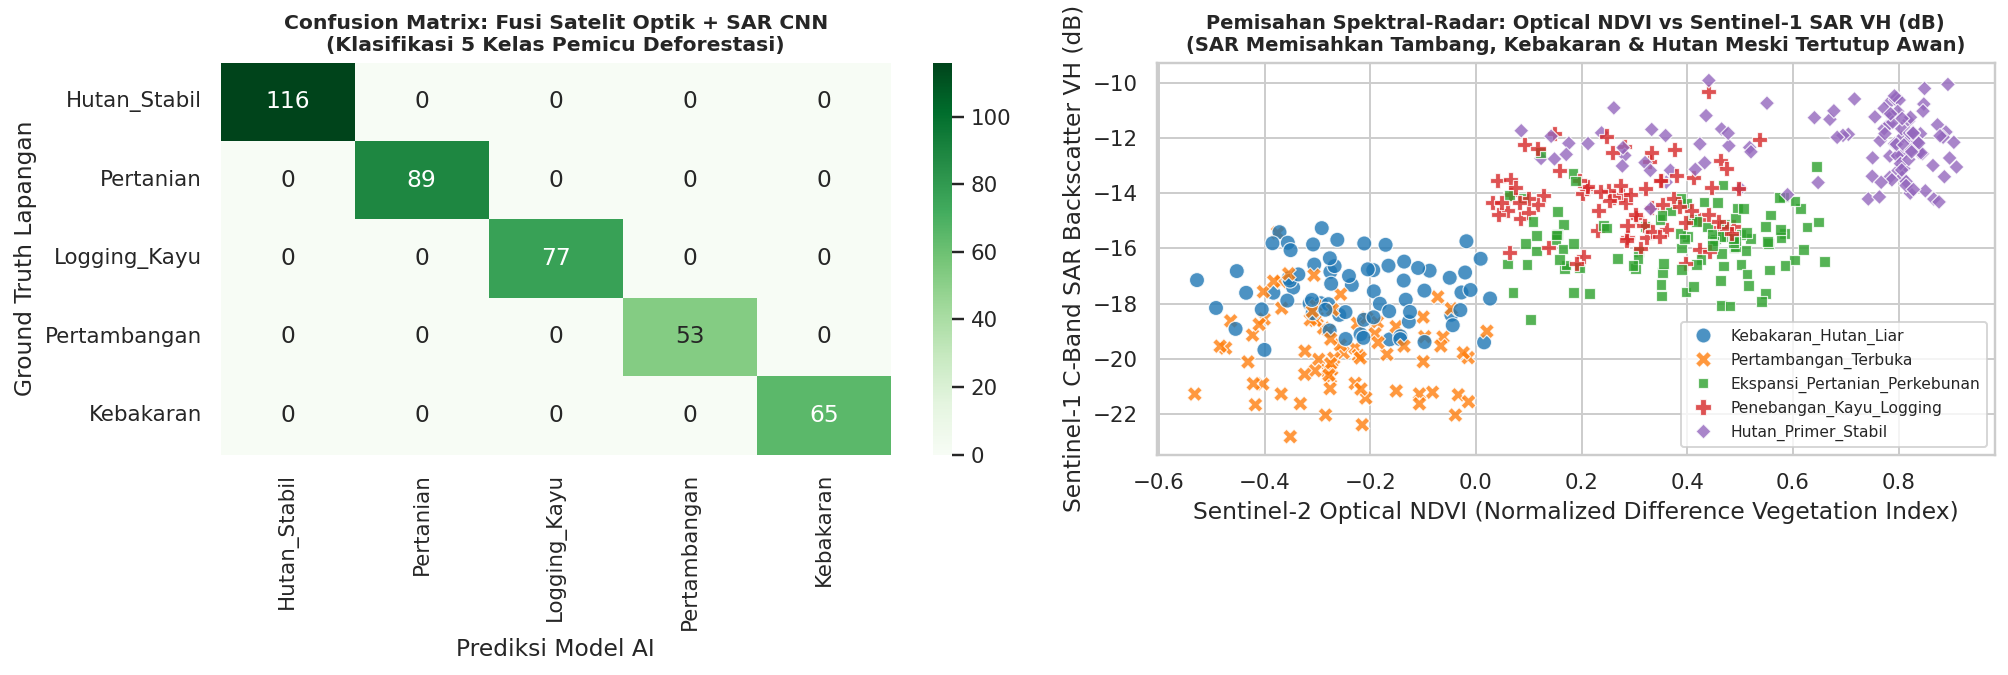

In [5]:
class_names_short = ["Hutan_Stabil", "Pertanian", "Logging_Kayu", "Pertambangan", "Kebakaran"]
conf_mat = np.zeros((n_classes, n_classes), dtype=int)
for yt, yp in zip(y_te, pred_fusion):
    conf_mat[yt, yp] += 1

df_te_alert = df_sat.iloc[te_i].copy()
id_to_name = dict(zip(df_sat["driver_class_id"], df_sat["driver_class_name"]))
df_te_alert["pred_driver"] = [id_to_name[i] for i in pred_fusion]
df_te_alert["confidence_score"] = np.max(prob_fusion, axis=1).round(4)

high_priority_alerts = df_te_alert[
    df_te_alert["pred_driver"].isin(["Pertambangan_Terbuka", "Kebakaran_Hutan_Liar", "Penebangan_Kayu_Logging"])
].sort_values("confidence_score", ascending=False).head(8)

print("=== TOP 8 PRIORITAS INVESTIGASI LAPANGAN & PENEGAKAN HUKUM LINGKUNGAN ===")
print(high_priority_alerts[["patch_id", "landscape_region", "cloud_cover_pct", "pred_driver", "confidence_score", "s1_sar_vh_db", "thermal_anomaly_kelvin"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Greens", xticklabels=class_names_short, yticklabels=class_names_short, ax=axes[0])
axes[0].set_title("Confusion Matrix: Fusi Satelit Optik + SAR CNN\n(Klasifikasi 5 Kelas Pemicu Deforestasi)", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Prediksi Model AI")
axes[0].set_ylabel("Ground Truth Lapangan")

sns.scatterplot(data=df_sat.sample(450, random_state=42), x="NDVI", y="s1_sar_vh_db",
                hue="driver_class_name", style="driver_class_name", s=60, alpha=0.8, ax=axes[1], palette="tab10")
axes[1].set_title("Pemisahan Spektral-Radar: Optical NDVI vs Sentinel-1 SAR VH (dB)\n(SAR Memisahkan Tambang, Kebakaran & Hutan Meski Tertutup Awan)", fontsize=10, fontweight="bold")
axes[1].set_xlabel("Sentinel-2 Optical NDVI (Normalized Difference Vegetation Index)")
axes[1].set_ylabel("Sentinel-1 C-Band SAR Backscatter VH (dB)")
axes[1].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()